In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("placementdata.csv")

In [3]:
df.shape()

(10000, 12)

In [4]:
df.head()

,StudentID,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus
0,1,7.5,1,1,1,65,4.4,No,No,61,79,NotPlaced
1,2,8.9,0,3,2,90,4.0,Yes,Yes,78,82,Placed
2,3,7.3,1,2,2,82,4.8,Yes,No,79,80,NotPlaced
3,4,7.5,1,1,2,85,4.4,Yes,Yes,81,80,Placed
4,5,8.3,1,2,2,86,4.5,Yes,Yes,74,88,Placed


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  10000 non-null  int64  
 1   CGPA                       10000 non-null  float64
 2   Internships                10000 non-null  int64  
 3   Projects                   10000 non-null  int64  
 4   Workshops/Certifications   10000 non-null  int64  
 5   AptitudeTestScore          10000 non-null  int64  
 6   SoftSkillsRating           10000 non-null  float64
 7   ExtracurricularActivities  10000 non-null  object 
 8   PlacementTraining          10000 non-null  object 
 9   SSC_Marks                  10000 non-null  int64  
 10  HSC_Marks                  10000 non-null  int64  
 11  PlacementStatus            10000 non-null  object 
dtypes: float64(2), int64(7), object(3)
memory usage: 937.6+ KB


No Missing values

convert softskillRating into float

In [7]:
df['SoftSkillsRating']=df['SoftSkillsRating'].astype('float')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  10000 non-null  int64  
 1   CGPA                       10000 non-null  float64
 2   Internships                10000 non-null  int64  
 3   Projects                   10000 non-null  int64  
 4   Workshops/Certifications   10000 non-null  int64  
 5   AptitudeTestScore          10000 non-null  int64  
 6   SoftSkillsRating           10000 non-null  float64
 7   ExtracurricularActivities  10000 non-null  object 
 8   PlacementTraining          10000 non-null  object 
 9   SSC_Marks                  10000 non-null  int64  
 10  HSC_Marks                  10000 non-null  int64  
 11  PlacementStatus            10000 non-null  object 
dtypes: float64(2), int64(7), object(3)
memory usage: 937.6+ KB


In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
StudentID,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
CGPA,10000.0,7.69801,0.640131,6.5,7.40,7.7,8.20,9.1
Internships,10000.0,1.04920,0.665901,0.0,1.00,1.0,1.00,2.0
Projects,10000.0,2.02660,0.867968,0.0,1.00,2.0,3.00,3.0
Workshops/Certifications,10000.0,1.01320,0.904272,0.0,0.00,1.0,2.00,3.0
AptitudeTestScore,10000.0,79.44990,8.159997,60.0,73.00,80.0,87.00,90.0
SoftSkillsRating,10000.0,4.32396,0.411622,3.0,4.00,4.4,4.70,4.8
SSC_Marks,10000.0,69.15940,10.430459,55.0,59.00,70.0,78.00,90.0
HSC_Marks,10000.0,74.50150,8.919527,57.0,67.00,73.0,83.00,88.0


In [14]:
df.corr(numeric_only=True)

,StudentID,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,SSC_Marks,HSC_Marks
StudentID,1.000000,0.005724,0.015655,0.015924,0.011872,0.020314,-0.002269,-0.003082,0.024115
CGPA,0.005724,1.000000,0.280601,0.435928,0.349686,0.461250,0.383547,0.404971,0.462313
Internships,0.015655,0.280601,1.000000,0.309196,0.279110,0.320725,0.273691,0.279837,0.317149
Projects,0.015924,0.435928,0.309196,1.000000,0.377865,0.540339,0.450294,0.499421,0.535708
Workshops/Certifications,0.011872,0.349686,0.279110,0.377865,1.000000,0.388061,0.342397,0.373045,0.418442
AptitudeTestScore,0.020314,0.461250,0.320725,0.540339,0.388061,1.000000,0.515400,0.513044,0.565105
SoftSkillsRating,-0.002269,0.383547,0.273691,0.450294,0.342397,0.515400,1.000000,0.430734,0.466912
SSC_Marks,-0.003082,0.404971,0.279837,0.499421,0.373045,0.513044,0.430734,1.000000,0.524916
HSC_Marks,0.024115,0.462313,0.317149,0.535708,0.418442,0.565105,0.466912,0.524916,1.000000


Observation

* All meaningful correlations are positive, indicating that improvement in one performance-related feature is generally associated with improvement in others.
* The strongest relationships are:
HSC_Marks ↔ AptitudeTestScore (0.565)
Projects ↔ AptitudeTestScore (0.540)
Projects ↔ HSC_Marks (0.536)
SSC_Marks ↔ HSC_Marks (0.525)
* No correlation exceeds 0.8, so there is no evidence of severe multicollinearity among the features. This means the variables can generally be used together in machine learning models without major multicollinearity concerns.

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.columns

Index(['StudentID', 'CGPA', 'Internships', 'Projects',
       'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating',
       'ExtracurricularActivities', 'PlacementTraining', 'SSC_Marks',
       'HSC_Marks', 'PlacementStatus'],
      dtype='object')

Categorical:-PlacementTraining,ExtraxcurricularActivites

Numerical :- CGPA,Internships,Projects,Workshops/Certification,AptitudeTestScore,SoftSkillsRating,ssc,hsc

Univariate Analysis

<Axes: xlabel='count', ylabel='ExtracurricularActivities'>

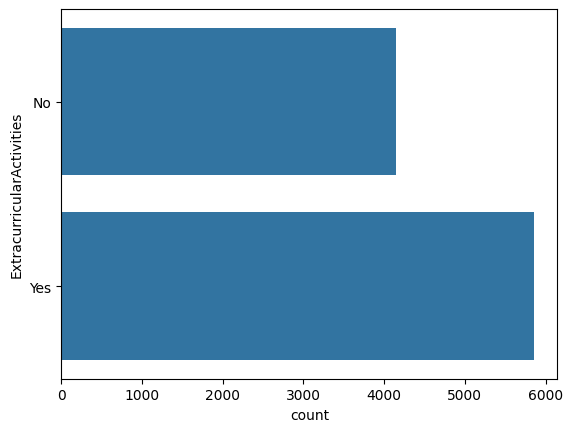

In [17]:
sns.countplot(df['ExtracurricularActivities'])

In [18]:
df['ExtracurricularActivities'].value_counts()

ExtracurricularActivities
Yes    5854
No     4146
Name: count, dtype: int64

<Axes: ylabel='count'>

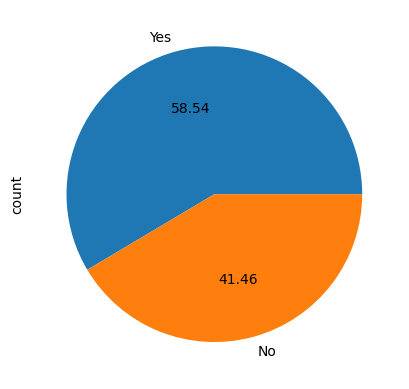

In [19]:
df['ExtracurricularActivities'].value_counts().plot(kind='pie',autopct='%.2f')

In [20]:
pd.crosstab(
    df['ExtracurricularActivities'],
    df['PlacementStatus']
)

PlacementStatus,NotPlaced,Placed
ExtracurricularActivities,,
No,3579,567
Yes,2224,3630


<Axes: xlabel='ExtracurricularActivities', ylabel='AptitudeTestScore'>

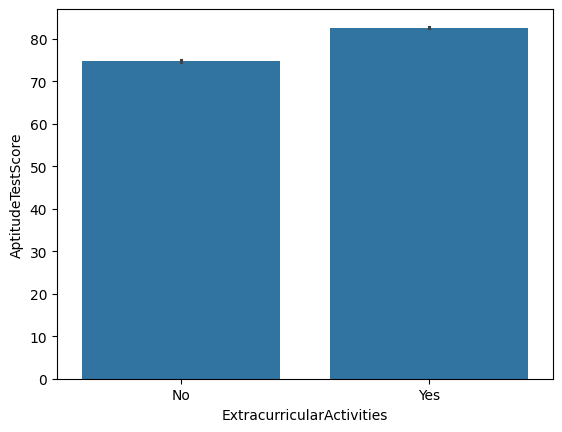

In [21]:
sns.barplot(
    x=df['ExtracurricularActivities'],
    y=df['AptitudeTestScore']
)

In [23]:
df.groupby('ExtracurricularActivities')['AptitudeTestScore'].mean()

ExtracurricularActivities
No     74.852870
Yes    82.705671
Name: AptitudeTestScore, dtype: float64

<Axes: xlabel='count', ylabel='PlacementTraining'>

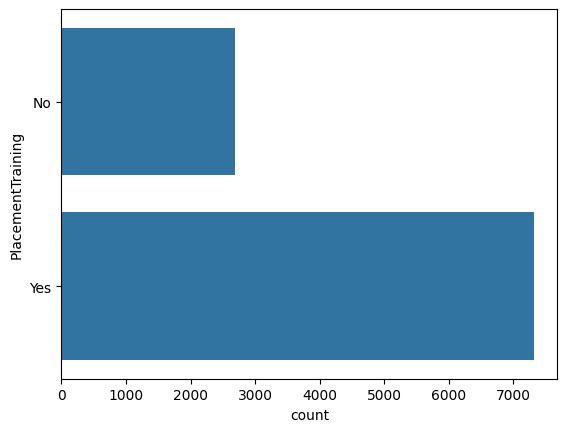

In [24]:
sns.countplot(df['PlacementTraining'])

In [25]:
pd.crosstab(
    df['PlacementTraining'],
    df['PlacementStatus']
)

PlacementStatus,NotPlaced,Placed
PlacementTraining,,
No,2264,418
Yes,3539,3779


In [28]:
# sns.histplot(x=df['CGPA'], kde=True)
# plt.show()

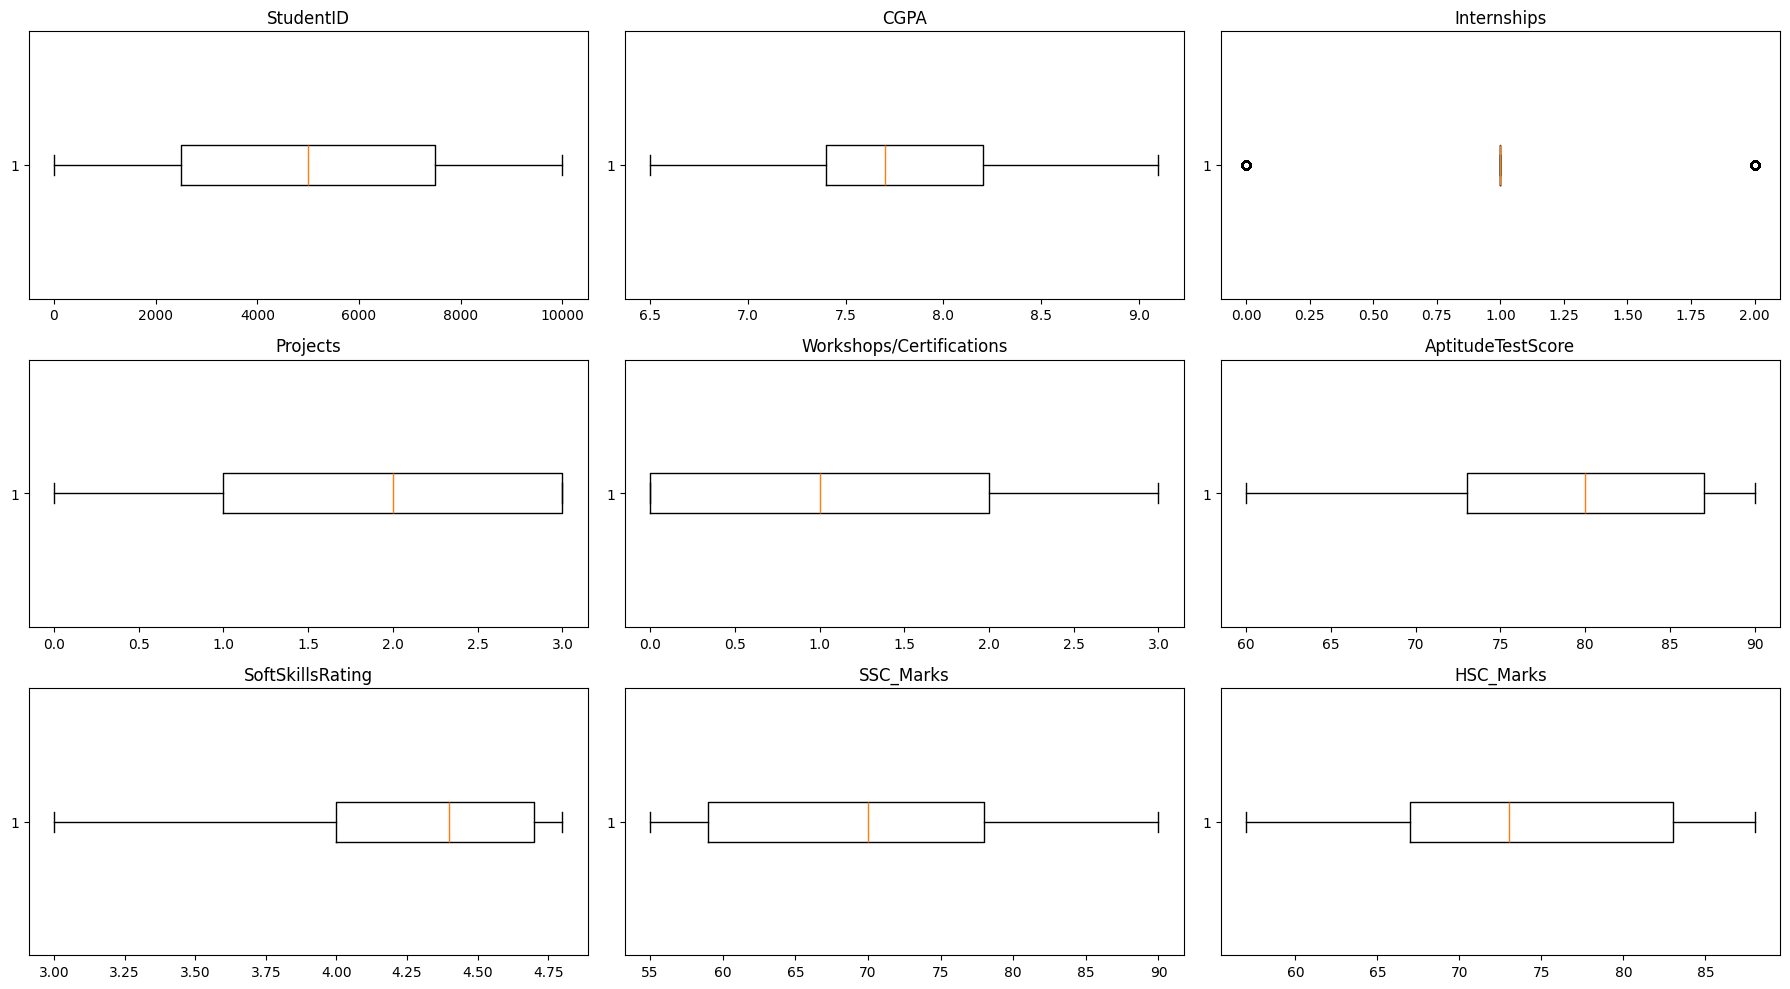

In [30]:
numeric_cols = df.select_dtypes(include=np.number).columns

# Boxplots before outlier treatment
plt.figure(figsize=(18, 10))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot((len(numeric_cols)+2)//3, 3, i)
    plt.boxplot(df[col], vert=False)
    plt.title(col)

plt.tight_layout()
plt.show()

In [31]:
df['AcademicScore'] = (df['SSC_Marks'] + df['HSC_Marks'] + df['CGPA']*10) / 3

In [32]:
df['ExperienceScore'] = df['Internships'] + df['Projects'] + df['Workshops/Certifications']

In [33]:
df['OverallSkillScore'] = (df['AptitudeTestScore'] + df['SoftSkillsRating']) / 2

In [34]:
df['AcademicImprovement'] = df['HSC_Marks'] - df['SSC_Marks']

In [35]:
df['ProjectsPerInternship'] = df['Projects'] / (df['Internships'] + 1)

In [36]:
df['CertificationRatio'] = df['Workshops/Certifications'] / (df['Projects'] + 1)

In [37]:
df['HighCGPA'] = np.where(df['CGPA'] >= 8, 1, 0)

In [38]:
df['AptitudeLevel'] = pd.cut(
    df['AptitudeTestScore'],
    bins=[0, 50, 70, 100],
    labels=['Low', 'Medium', 'High']
)

In [39]:
df['AchievementScore'] = (
    df['Projects'] +
    df['Internships'] +
    df['Workshops/Certifications']
)

In [40]:
df['CGPA_Aptitude'] = df['CGPA'] * df['AptitudeTestScore']

In [41]:


df.head()

,StudentID,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,...,AcademicScore,ExperienceScore,OverallSkillScore,AcademicImprovement,ProjectsPerInternship,CertificationRatio,HighCGPA,AptitudeLevel,AchievementScore,CGPA_Aptitude
0,1,7.5,1,1,1,65,4.4,No,No,61,...,71.666667,3,34.70,18,0.5,0.500000,0,Medium,3,487.5
1,2,8.9,0,3,2,90,4.0,Yes,Yes,78,...,83.000000,5,47.00,4,3.0,0.500000,1,High,5,801.0
2,3,7.3,1,2,2,82,4.8,Yes,No,79,...,77.333333,5,43.40,1,1.0,0.666667,0,High,5,598.6
3,4,7.5,1,1,2,85,4.4,Yes,Yes,81,...,78.666667,4,44.70,-1,0.5,1.000000,0,High,4,637.5
4,5,8.3,1,2,2,86,4.5,Yes,Yes,74,...,81.666667,5,45.25,14,1.0,0.666667,1,High,5,713.8


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

ModuleNotFoundError: No module named 'sklearn'

In [ ]:
df['AptitudeLevel'] = df['AptitudeLevel'].map({
    'Low': 0,
    'Medium': 1,
    'High': 2
})